# EV Charging Demand Prediction & Usage Pattern Analysis
## Part 2: Regression, Classification, Time Series Forecasting & XAI

### Contents:
1. **Regression:** Predict continuous Demand (kWh) using Linear Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost, LightGBM (evaluated with MAE, MSE, RMSE, R²).
2. **Classification:** Predict High-Demand vs Normal-Demand sessions, evaluate class imbalance techniques (Random Oversampling, SMOTE, ADASYN), and benchmark 7 algorithms.
3. **Time Series Forecasting:** Check ADF stationarity, Moving Average, and Exponential Smoothing (evaluated with MAE & RMSE).
4. **Explainable AI:** Feature Importance, SHAP, and LIME interpretability.

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

print("Libraries ready!")

Libraries ready!


### 1. Load Processed Dataset & Models

In [2]:
data_path = os.path.join('..', 'data', 'processed', 'cleaned_charging_records.csv')
df = pd.read_csv(data_path)
print(f"Loaded clean data: {df.shape}")

# Load saved metrics summary
with open(os.path.join('..', 'models', 'evaluation_metrics.json'), 'r') as f:
    metrics = json.load(f)

print(f"Best Regression Model: {metrics['best_regression_model']}")
print(f"Best Classification Model: {metrics['best_classification_model']}")

Loaded clean data: (72421, 28)
Best Regression Model: Random Forest
Best Classification Model: XGBoost


### 2. Regression Models Performance Comparison

In [3]:
reg_df = pd.DataFrame(metrics['regression_metrics']).T.sort_values(by='R2', ascending=False)
print("=== Regression Model Comparison (Target: Demand kWh) ===")
reg_df

=== Regression Model Comparison (Target: Demand kWh) ===

,MAE,MSE,RMSE,R2
Random Forest,3.3767,36.9744,6.0807,0.7983
XGBoost,3.4301,37.4713,6.1214,0.7956
LightGBM,3.4760,37.9694,6.1619,0.7929
Gradient Boosting,3.5090,38.8925,6.2364,0.7878
Decision Tree,3.5226,45.4999,6.7454,0.7518
Linear Regression,5.6098,75.4945,8.6888,0.5882


C:\Users\packi\AppData\Local\Temp\ipykernel_19252\3999477532.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=reg_df.index, y=reg_df['R2'], palette='crest')


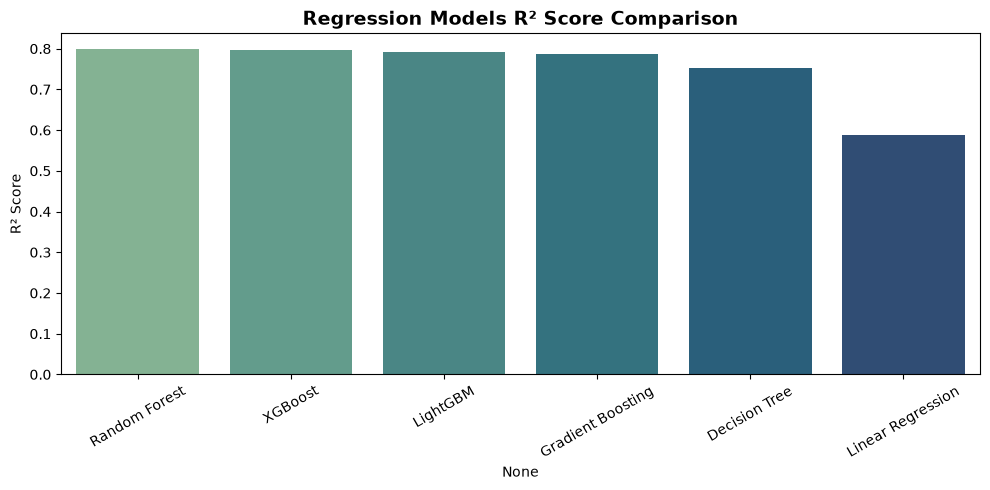

In [4]:
plt.figure(figsize=(10, 5))
sns.barplot(x=reg_df.index, y=reg_df['R2'], palette='crest')
plt.title('Regression Models R² Score Comparison', fontsize=14, fontweight='bold')
plt.ylabel('R² Score')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 3. Classification Models Benchmark & Imbalance Handling

In [5]:
clf_df = pd.DataFrame(metrics['classification_metrics']).T.sort_values(by='F1', ascending=False)
print("=== Classification Model Comparison (Target: High Demand) ===")
clf_df

=== Classification Model Comparison (Target: High Demand) ===


,Accuracy,Precision,Recall,F1,ROC_AUC
XGBoost,0.9013,0.8745,0.9364,0.9044,0.9615
LightGBM,0.9009,0.8730,0.9375,0.9041,0.9610
Random Forest,0.8980,0.8657,0.9413,0.9019,0.9562
Decision Tree,0.8920,0.8736,0.9156,0.8941,0.9299
Logistic Regression,0.8434,0.8280,0.8656,0.8464,0.9146
SVM,0.8112,0.7989,0.8300,0.8142,0.8954
KNN,0.7817,0.7771,0.7879,0.7825,0.8602


In [6]:
imb_df = pd.DataFrame(metrics['imbalance_comparison']).T
print("=== Class Imbalance Technique Comparison ===")
imb_df

=== Class Imbalance Technique Comparison ===


,Accuracy,Precision,Recall,F1,ROC_AUC
Baseline (No Resampling),0.8992,0.8923,0.8315,0.8608,0.9566
Random Oversampling,0.9089,0.8518,0.9164,0.8829,0.9587
SMOTE,0.9108,0.8552,0.9175,0.8852,0.9588
ADASYN,0.9134,0.8478,0.9374,0.8903,0.9600


### 4. Time Series Forecasting & Trend Analysis
- Augmented Dickey-Fuller (ADF) Stationarity Test
- Moving Average (7-Day & 30-Day Rolling)
- Additive Seasonal Decomposition (Trend, Seasonality, Noise)
- Exponential Smoothing (Simple & Holt-Winters Seasonal)

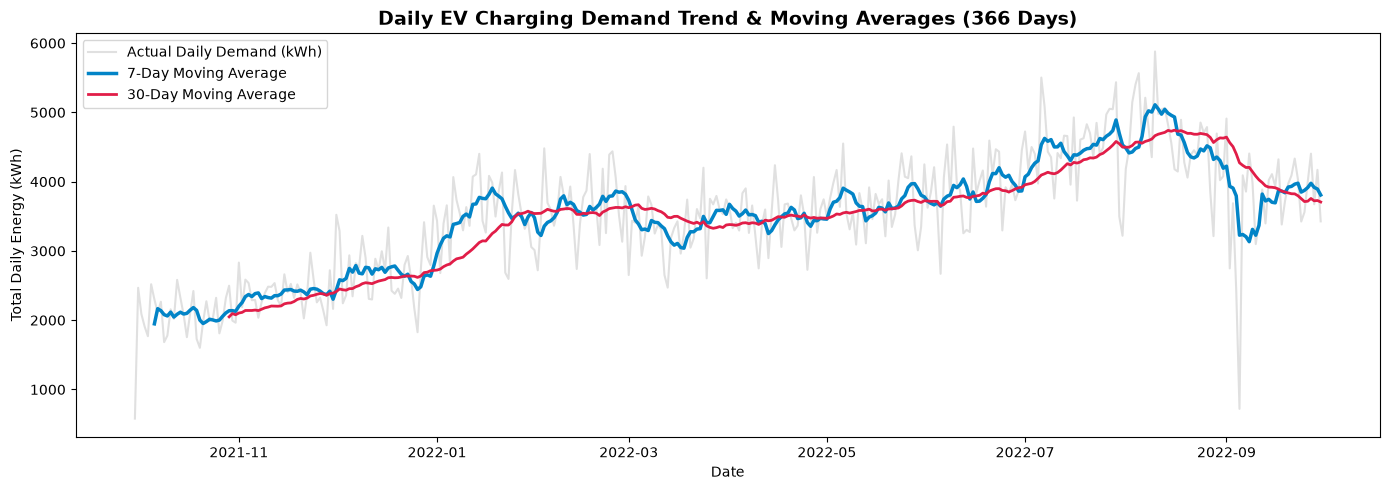

In [7]:
daily_ts = pd.read_csv(os.path.join('..', 'models', 'daily_timeseries.csv'))
daily_ts['Date'] = pd.to_datetime(daily_ts['Date'])
daily_ts['7D_MA'] = daily_ts['Total_Demand_kWh'].rolling(7).mean()
daily_ts['30D_MA'] = daily_ts['Total_Demand_kWh'].rolling(30).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_ts['Date'], daily_ts['Total_Demand_kWh'], color='lightgray', alpha=0.7, label='Actual Daily Demand (kWh)')
plt.plot(daily_ts['Date'], daily_ts['7D_MA'], color='#0284c7', linewidth=2.5, label='7-Day Moving Average')
plt.plot(daily_ts['Date'], daily_ts['30D_MA'], color='#e11d48', linewidth=2, label='30-Day Moving Average')
plt.title('Daily EV Charging Demand Trend & Moving Averages (366 Days)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Daily Energy (kWh)')
plt.legend()
plt.tight_layout()
plt.show()

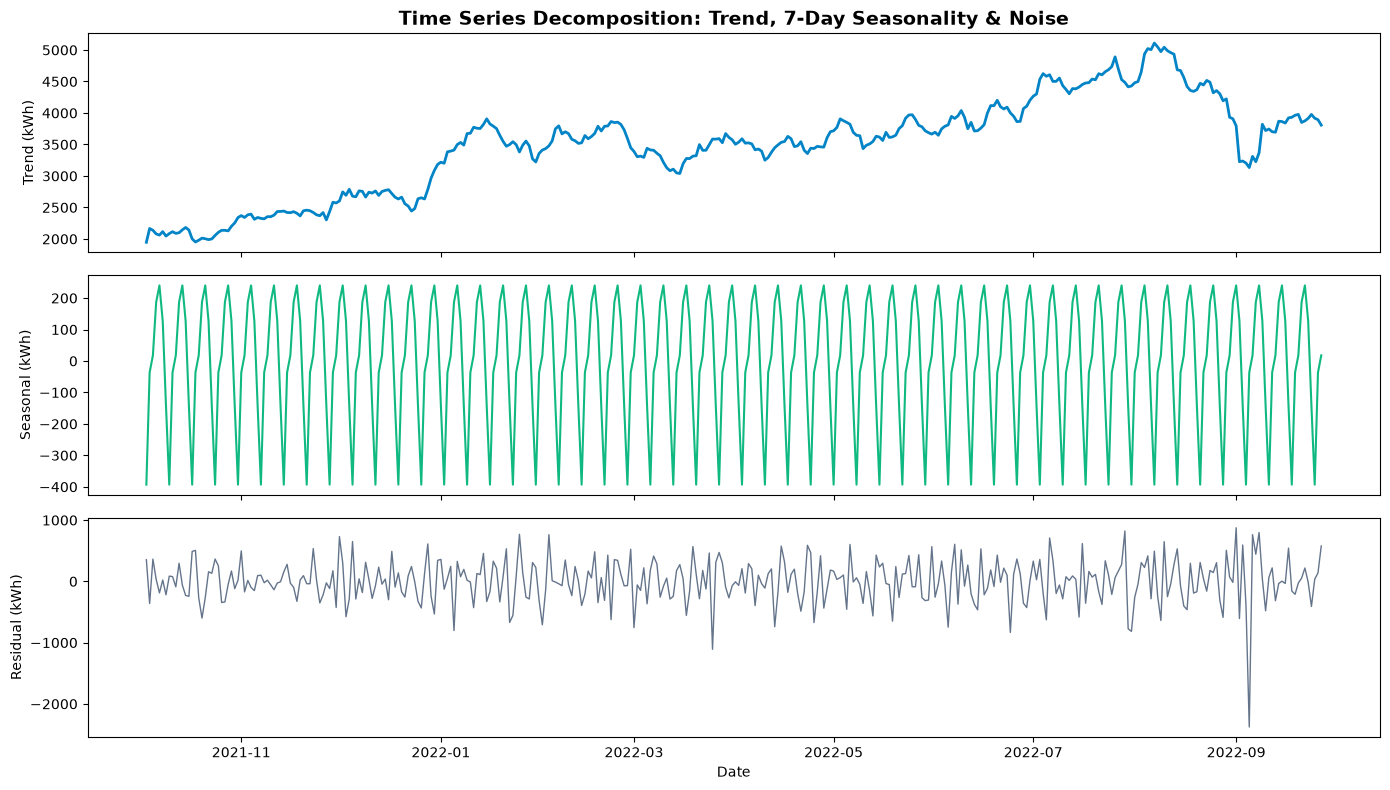

In [8]:
decomp_path = os.path.join('..', 'models', 'timeseries_decomposition.csv')
if os.path.exists(decomp_path):
    decomp_df = pd.read_csv(decomp_path)
    decomp_df['Date'] = pd.to_datetime(decomp_df['Date'])
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(decomp_df['Date'], decomp_df['Trend'], color='#0284c7', linewidth=2)
    axes[0].set_ylabel('Trend (kWh)')
    axes[0].set_title('Time Series Decomposition: Trend, 7-Day Seasonality & Noise', fontsize=14, fontweight='bold')
    axes[1].plot(decomp_df['Date'], decomp_df['Seasonal'], color='#10b981', linewidth=1.5)
    axes[1].set_ylabel('Seasonal (kWh)')
    axes[2].plot(decomp_df['Date'], decomp_df['Residual'], color='#64748b', linewidth=1)
    axes[2].set_ylabel('Residual (kWh)')
    axes[2].set_xlabel('Date')
    plt.tight_layout()
    plt.show()

In [9]:
ts_models = pd.DataFrame(metrics['timeseries_metrics']['Models']).T
print('=== Time Series Forecasting Benchmark ===')
print(f"ADF Test Statistic : {metrics['timeseries_metrics']['Stationarity_ADF']['ADF_Statistic']:.4f}")
print(f"ADF p-value        : {metrics['timeseries_metrics']['Stationarity_ADF']['p_value']:.4e}")
print(f"Is Stationary      : {metrics['timeseries_metrics']['Stationarity_ADF']['Is_Stationary']} (Non-Stationary Growth Trend)")
ts_models

=== Time Series Forecasting Benchmark ===
ADF Test Statistic : -1.8800
ADF p-value        : 3.4153e-01
Is Stationary      : False (Non-Stationary Growth Trend)


,MAE,RMSE
Moving Average (7-Day),581.46,892.01
Simple Exponential Smoothing,620.66,925.48
Holt-Winters Exponential Smoothing,729.00,978.22


### 5. Explainable AI (SHAP & LIME)

In [10]:
import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

reg_model = joblib.load(os.path.join('..', 'models', 'regression_model.pkl'))
preprocessor = joblib.load(os.path.join('..', 'models', 'preprocessor.pkl'))
shap_sample = pd.read_csv(os.path.join('..', 'models', 'shap_sample_data.csv'))

feature_cols = metrics['categorical_columns'] + metrics['numerical_columns']
X_sample_proc = preprocessor.transform(shap_sample[feature_cols])

cat_encoder = preprocessor.named_transformers_['cat']
cat_features = cat_encoder.get_feature_names_out(metrics['categorical_columns'])
all_features = list(cat_features) + metrics['numerical_columns']

print("Top 10 Feature Importances:")
feat_imp = pd.Series(reg_model.feature_importances_, index=all_features).sort_values(ascending=False).head(10)
print(feat_imp)

Top 10 Feature Importances:
Duration_Mins             0.799317
ChargerType_1             0.030303
ChargerType_Avg_Demand    0.027090
ChargerType_0             0.021479
StartMonth                0.020412
StartDay                  0.013819
Hour_Cos                  0.011475
Loc_Avg_Demand            0.010585
StartHour                 0.008557
Hour_Sin                  0.008395
dtype: float64
